# Notebook 03 — Logistic Regression

**Research topic:** *A Machine Learning Approach to Predicting Retail Investor Dormancy on Digital Investment Platforms*

This notebook independently develops and evaluates the **Logistic Regression** model.

The modelling dataset comes from the feature-engineering notebook. The notebook includes preprocessing required specifically for Logistic Regression, model training, hyperparameter specification, predictions, evaluation metrics, a confusion matrix and an ROC curve.


In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, 
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

DATA_FILE = Path("outputs/dormancy_modelling_dataset.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
THRESHOLD = 0.50

df = pd.read_csv(DATA_FILE)

X = df.drop(columns=["customer_id", "dormant"])
y = df["dormant"]

categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = [c for c in X.columns if c not in categorical_cols]

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print("Dataset shape:", df.shape)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Dormancy distribution:")
display(y.value_counts())


Dataset shape: (48723, 38)
Training rows: 38978
Testing rows: 9745
Dormancy distribution:


dormant
0    47943
1      780
Name: count, dtype: int64

## Logistic Regression preprocessing

Logistic Regression is sensitive to feature scale. Therefore:

- Missing numerical values are replaced using the median.
- Numerical variables are standardised.
- Missing categorical values are replaced using the most frequent category.
- Categorical variables are one-hot encoded.
- `class_weight="balanced"` is used to account for class imbalance.


In [2]:

numeric_pipeline = Pipeline([ ("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()) 
                            ])


categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))
                                ])


preprocessor = ColumnTransformer([("num", numeric_pipeline, numeric_cols), ("cat", categorical_pipeline, categorical_cols)
                                 ])


## Logistic Regression model

The model uses:

- **C = 1.0**
- **solver = `liblinear`**
- **class weight = `balanced`**
- **maximum iterations = 1000**
- **random state = 42**

`class_weight="balanced"` gives greater importance to the minority dormant class during training.


In [3]:

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        solver="liblinear",
        max_iter=1000,
        random_state=RANDOM_STATE))])

logistic_model.fit(X_train, y_train)

lr_prob = logistic_model.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= THRESHOLD).astype(int)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


## Model evaluation

In [4]:

lr_metrics = {
    "Accuracy": accuracy_score(y_test, lr_pred),
    "Precision": precision_score(y_test, lr_pred, zero_division=0),
    "Recall": recall_score(y_test, lr_pred, zero_division=0),
    "F1-score": f1_score(y_test, lr_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, lr_prob)}

display(pd.DataFrame([lr_metrics]).round(4))

print(classification_report(y_test, lr_pred, target_names=["Non-dormant", "Dormant"], digits=4, zero_division=0))

pd.DataFrame([lr_metrics]).to_csv( OUTPUT_DIR / "logistic_regression_metrics.csv", index=False)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.6166,0.0348,0.859,0.0669,0.7866


              precision    recall  f1-score   support

 Non-dormant     0.9963    0.6127    0.7587      9589
     Dormant     0.0348    0.8590    0.0669       156

    accuracy                         0.6166      9745
   macro avg     0.5155    0.7358    0.4128      9745
weighted avg     0.9809    0.6166    0.7477      9745



## Confusion matrix

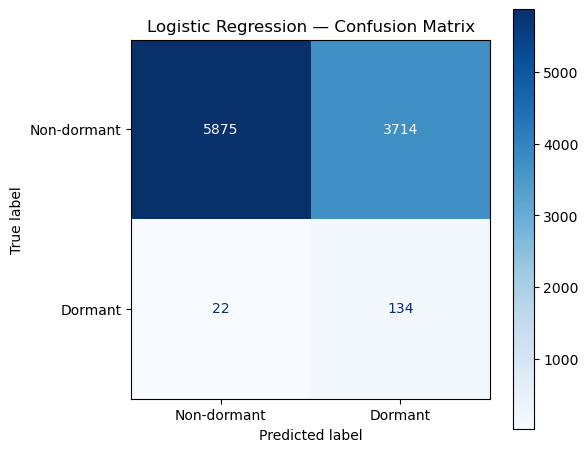

In [5]:

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, display_labels=["Non-dormant", "Dormant"], cmap="Blues", ax=ax)

ax.set_title("Logistic Regression — Confusion Matrix")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "logistic_regression_confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()


## ROC curve

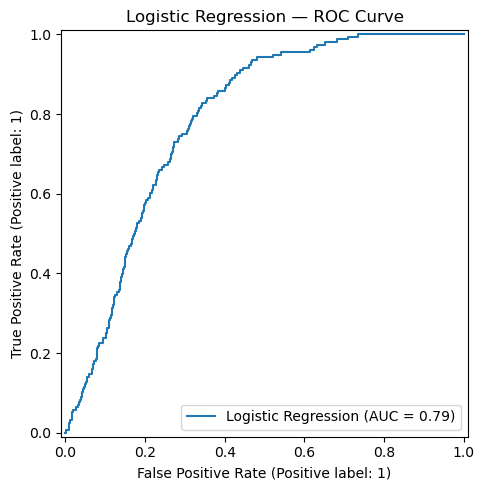

In [6]:

fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(y_test, lr_prob, name="Logistic Regression", ax=ax)

ax.set_title("Logistic Regression — ROC Curve")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "logistic_regression_roc_curve.png", dpi=300, bbox_inches="tight")

plt.show()


## Logistic Regression output

This notebook produces:

- `logistic_regression_metrics.csv`
- `logistic_regression_confusion_matrix.png`
- `logistic_regression_roc_curve.png`

The saved metrics can later be used in the model-comparison notebook.
